## Implementation of Linear regression using python

In [1]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [4]:
DF1=pd.read_csv("weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [5]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

### Standardize numerical features

In [6]:
col=["Height","Weight"]
S1=MinMaxScaler()
DF1[col]=S1.fit_transform(DF1[col])
DF1.head()

,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [7]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

In [8]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

## Split the data into training and test set

In [9]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [10]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [34]:
## Training  Linear regressions model 

In [11]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [12]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


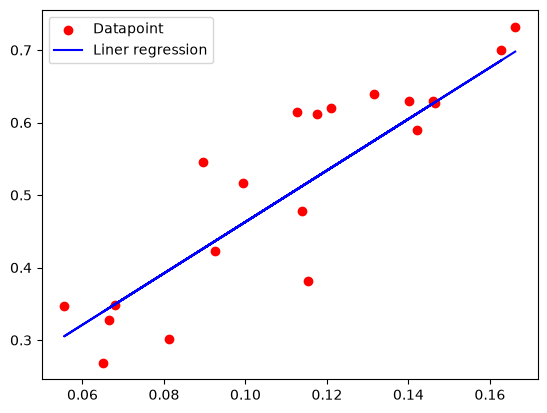

In [13]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()

In [38]:
## Load the Height and weight  to indipendent and dependent variable 

In [14]:
DF2=pd.read_csv("Weight-height.csv")
X=DF2['Height'].values.reshape(-1,1)
X.shape
Y=DF2["Weight"].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [15]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [16]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [17]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)


(10000, 2)
(2, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

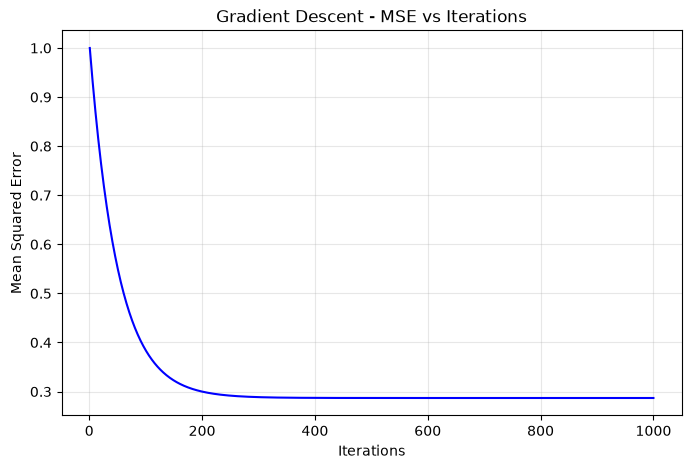

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, len(mseh) + 1), mseh, color="blue")

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent - MSE vs Iterations")
plt.grid(True, alpha=0.3)

plt.show()

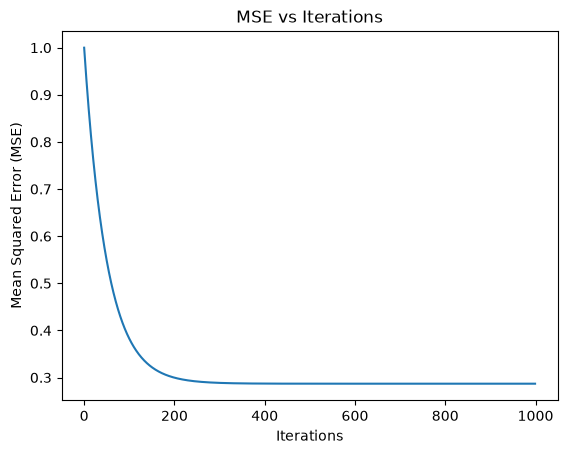

In [36]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [38]:
DF = pd.read_csv("Food_Delivery_Times.csv")

DF.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [39]:
print("Dataset Shape:", DF.shape)
print("\nDataset Information:")
DF.info()

print("\nMissing Values:")
print(DF.isnull().sum())

Dataset Shape: (1000, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 70.4 KB

Missing Values:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min      

In [40]:
print(DF.columns.tolist())

['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']


In [41]:

X = DF[
    [
        "Distance_km",
        "Preparation_Time_min",
        "Traffic_Level",
        "Weather"
    ]
]

Y = DF["Delivery_Time_min"]

print("Independent Variables:")
display(X.head())

print("Dependent Variable:")
display(Y.head())


Independent Variables:


,Distance_km,Preparation_Time_min,Traffic_Level,Weather
0,7.93,12,Low,Windy
1,16.42,20,Medium,Clear
2,9.52,28,Low,Foggy
3,7.44,5,Medium,Rainy
4,19.03,16,Low,Clear


Dependent Variable:


0    43
1    84
2    59
3    37
4    68
Name: Delivery_Time_min, dtype: int64

In [9]:
X = pd.get_dummies(
    X,
    columns=["Traffic_Level", "Weather"],
    drop_first=True,
    dtype=int
)

print("Encoded Independent Variables:")
display(X.head())

print("\nEncoded Feature Names:")
print(X.columns.tolist())

Encoded Independent Variables:


,Distance_km,Preparation_Time_min,Traffic_Level_Low,Traffic_Level_Medium,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,7.93,12,1,0,0,0,0,1
1,16.42,20,0,1,0,0,0,0
2,9.52,28,1,0,1,0,0,0
3,7.44,5,0,1,0,1,0,0
4,19.03,16,1,0,0,0,0,0



Encoded Feature Names:
['Distance_km', 'Preparation_Time_min', 'Traffic_Level_Low', 'Traffic_Level_Medium', 'Weather_Foggy', 'Weather_Rainy', 'Weather_Snowy', 'Weather_Windy']


In [42]:
X = pd.get_dummies(
    X,
    columns=["Traffic_Level", "Weather"],
    drop_first=True,
    dtype=int
)

print("Encoded Independent Variables:")
display(X.head())

print("\nEncoded Feature Names:")
print(X.columns.tolist())

Encoded Independent Variables:


,Distance_km,Preparation_Time_min,Traffic_Level_Low,Traffic_Level_Medium,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,7.93,12,1,0,0,0,0,1
1,16.42,20,0,1,0,0,0,0
2,9.52,28,1,0,1,0,0,0
3,7.44,5,0,1,0,1,0,0
4,19.03,16,1,0,0,0,0,0



Encoded Feature Names:
['Distance_km', 'Preparation_Time_min', 'Traffic_Level_Low', 'Traffic_Level_Medium', 'Weather_Foggy', 'Weather_Rainy', 'Weather_Snowy', 'Weather_Windy']


In [43]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=67
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)
print("Training Target Shape:", Y_train.shape)
print("Testing Target Shape:", Y_test.shape)

Training Data Shape: (800, 8)
Testing Data Shape: (200, 8)
Training Target Shape: (800,)
Testing Target Shape: (200,)


In [44]:
model = LinearRegression()

model.fit(X_train, Y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [45]:
Y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Delivery Time": Y_test.values,
    "Predicted Delivery Time": Y_pred
})

display(results.head(10))

,Actual Delivery Time,Predicted Delivery Time
0,57,55.467352
1,67,57.534734
2,68,72.785085
3,28,32.940943
4,42,39.687967
5,47,49.555933
6,54,48.831967
7,28,32.126049
8,60,51.288492
9,68,82.349829


In [46]:
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R2) Score:", r2)

Mean Squared Error (MSE): 92.45559169586787
Root Mean Squared Error (RMSE): 9.615383075877313
Mean Absolute Error (MAE): 6.58095641660729
R-squared (R2) Score: 0.821181900301027


In [47]:
print("Model Intercept:")
print(model.intercept_)

print("\nModel Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Model Intercept:
14.937737098447386

Model Coefficients:
Distance_km : 2.933755775180072
Preparation_Time_min : 0.9627234912839479
Traffic_Level_Low : -11.726130368230336
Traffic_Level_Medium : -6.196221352821259
Weather_Foggy : 8.390824916790404
Weather_Rainy : 4.735778307940365
Weather_Snowy : 9.359024850458278
Weather_Windy : 1.0591537395116295


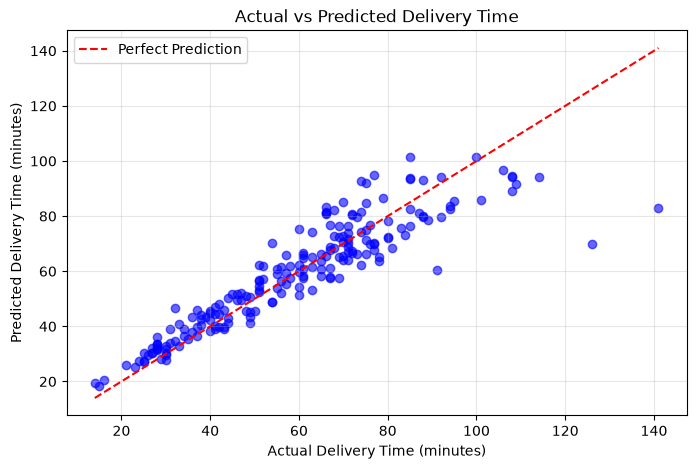

In [48]:
plt.figure(figsize=(8, 5))

plt.scatter(Y_test, Y_pred, color="blue", alpha=0.6)

min_value = min(Y_test.min(), Y_pred.min())
max_value = max(Y_test.max(), Y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

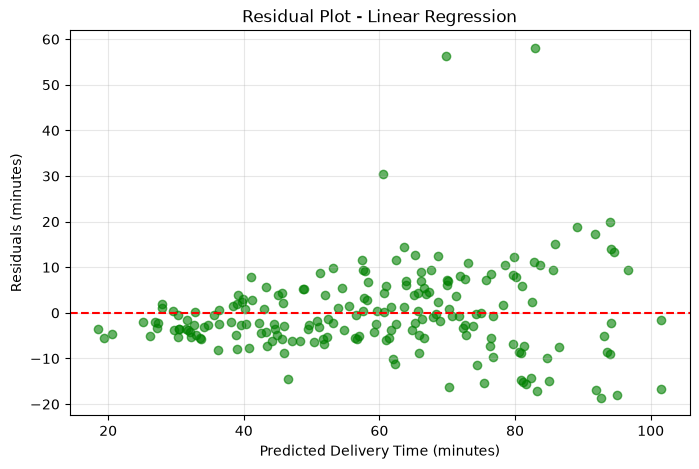

In [49]:
residuals = Y_test.values - Y_pred

plt.figure(figsize=(8, 5))

plt.scatter(Y_pred, residuals, color="green", alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Delivery Time (minutes)")
plt.ylabel("Residuals (minutes)")
plt.title("Residual Plot - Linear Regression")
plt.grid(True, alpha=0.3)

plt.show()


In [50]:
X_gd = X.to_numpy(dtype=float)
Y_gd = Y.to_numpy(dtype=float).reshape(-1, 1)

# Z-score normalization of independent variables
X_mean = X_gd.mean(axis=0)
X_std = X_gd.std(axis=0)
X_std[X_std == 0] = 1

X_scaled = (X_gd - X_mean) / X_std

# Z-score normalization of dependent variable
Y_mean = Y_gd.mean()
Y_std = Y_gd.std()

Y_scaled = (Y_gd - Y_mean) / Y_std

# Add bias column
X_gd = np.hstack((
    np.ones((X_scaled.shape[0], 1)),
    X_scaled
))

# Split using the same random state
X_train_gd, X_test_gd, Y_train_gd, Y_test_gd = train_test_split(
    X_gd,
    Y_scaled,
    test_size=0.2,
    random_state=67
)

print("Training shape:", X_train_gd.shape)
print("Testing shape:", X_test_gd.shape)

Training shape: (800, 9)
Testing shape: (200, 9)


In [39]:
theta = np.zeros((X_train_gd.shape[1], 1))

iterations = 1000
learning_rate = 0.01
m = len(Y_train_gd)

mse_history = []

# Gradient Descent
for i in range(iterations):
    Y_pred_gd = np.dot(X_train_gd, theta)

    error = Y_pred_gd - Y_train_gd

    mse = np.mean(error ** 2)
    mse_history.append(mse)

    gradient = (2 / m) * np.dot(X_train_gd.T, error)

    theta = theta - learning_rate * gradient

print("Gradient Descent Completed")
print("Final Training MSE:", mse_history[-1])
print("Final Parameters:")
print(theta.flatten())

Gradient Descent Completed
Final Training MSE: 0.24482050290379956
Final Parameters:
[ 1.69880633e-05  7.57227002e-01  3.14262137e-01 -2.58268719e-01
 -1.36870927e-01  1.15622287e-01  8.65197389e-02  1.25569159e-01
  1.41544773e-02]


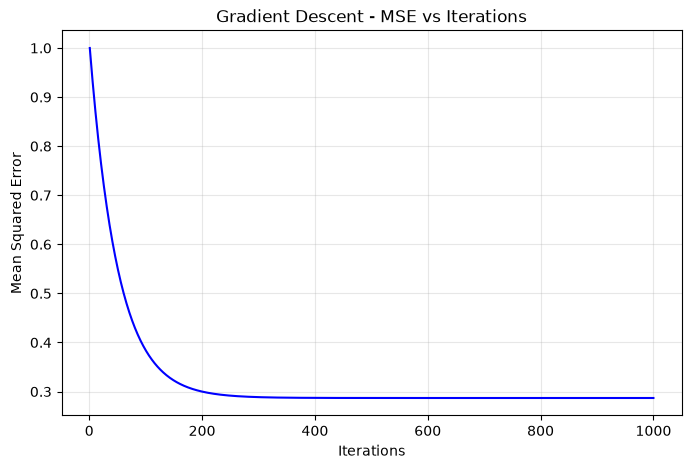

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, len(mseh) + 1), mseh, color="blue")

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent - MSE vs Iterations")
plt.grid(True, alpha=0.3)

plt.show()

In [56]:
Y_pred_gd_scaled = np.dot(X_test_gd, theta)

Y_pred_gd = Y_pred_gd_scaled * Y_std + Y_mean
Y_test_actual = Y_test_gd * Y_std + Y_mean

mse_gd = mean_squared_error(Y_test_actual, Y_pred_gd)
rmse_gd = np.sqrt(mse_gd)
mae_gd = mean_absolute_error(Y_test_actual, Y_pred_gd)
r2_gd = r2_score(Y_test_actual, Y_pred_gd)

print("Gradient Descent Evaluation")
print("MSE:", mse_gd)
print("RMSE:", rmse_gd)
print("MAE:", mae_gd)
print("R2 Score:", r2_gd)

ValueError: shapes (200,9) and (2,) not aligned: 9 (dim 1) != 2 (dim 0)

In [57]:
print("X_train_gd:", X_train_gd.shape)
print("X_test_gd:", X_test_gd.shape)
print("theta:", theta.shape)
print("Y_test_gd:", Y_test_gd.shape)

X_train_gd: (800, 9)
X_test_gd: (200, 9)
theta: (2,)
Y_test_gd: (200, 1)


In [58]:
# Initialize theta for 9 features
theta = np.zeros((X_train_gd.shape[1], 1))

learningrate = 0.01
iterations = 1000
mseh = []

# Gradient Descent
for i in range(iterations):
    y_pred = np.dot(X_train_gd, theta)

    error = y_pred - Y_train_gd

    mse = mean_squared_error(Y_train_gd, y_pred)
    mseh.append(mse)

    gradient = np.dot(X_train_gd.T, error) / len(Y_train_gd)

    theta -= learningrate * gradient

print("Gradient Descent Training Completed!")
print("Theta shape:", theta.shape)

Gradient Descent Training Completed!
Theta shape: (9, 1)


In [59]:
Y_pred_gd_scaled = np.dot(X_test_gd, theta)

Y_pred_gd = Y_pred_gd_scaled * Y_std + Y_mean
Y_test_actual = Y_test_gd * Y_std + Y_mean

mse_gd = mean_squared_error(Y_test_actual, Y_pred_gd)
rmse_gd = np.sqrt(mse_gd)
mae_gd = mean_absolute_error(Y_test_actual, Y_pred_gd)
r2_gd = r2_score(Y_test_actual, Y_pred_gd)

print("Gradient Descent Evaluation")
print("MSE:", mse_gd)
print("RMSE:", rmse_gd)
print("MAE:", mae_gd)
print("R2 Score:", r2_gd)

Gradient Descent Evaluation
MSE: 92.22304761440421
RMSE: 9.60328316850046
MAE: 6.567811729165638
R2 Score: 0.8216316631545315
